In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import sys
import cv2 as cv

from pycocotools.coco import COCO
from pathlib import Path
from IPython.display import display
from matplotlib.patches import Rectangle

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.data_prep import CLASSES, get_data_summary, load_annotations, prepare_annotations

In [ ]:
DIRECTORY = PROJECT_ROOT / "data"
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
INFO_TRAIN = DIRECTORY / "train" / "annotations_coco.json"
INFO_VAL = DIRECTORY / "val" / "annotations_coco.json"
INFO_TEST = DIRECTORY / "test_images.csv"

## Load annotations

In [6]:
train_coco, val_coco = COCO(str(INFO_TRAIN)), COCO(str(INFO_VAL))
summary_train, summary_val, summary_test = get_data_summary(train_coco), get_data_summary(val_coco), get_data_summary(str(INFO_TEST))
summaries = {"train": summary_train, "val": summary_val, "test": summary_test}
summary = pd.DataFrame.from_dict(summaries, orient="index")

display(summary)

loading annotations into memory...
Done (t=2.29s)
creating index...
index created!
loading annotations into memory...
Done (t=0.18s)
creating index...
index created!


,clips,frames,min_width,max_width,min_height,max_height
train,56,24201,1344,2720,756,1530
val,7,2846,1344,3840,756,2160
test,48,3811,680,1920,382,1080


In [7]:
train_frames, train_boxes = load_annotations(train_coco, "train")
val_frames, val_boxes = load_annotations(val_coco, "val")

frames = pd.concat([train_frames, val_frames], ignore_index=True)
boxes = pd.concat([train_boxes, val_boxes], ignore_index=True)

correct_boxes, ignored_boxes = prepare_annotations(boxes)
print(f"Correct boxes: {len(correct_boxes)}")
print(f"Ignored boxes: {len(ignored_boxes)}")

Correct boxes: 1219648
Ignored boxes: 542704


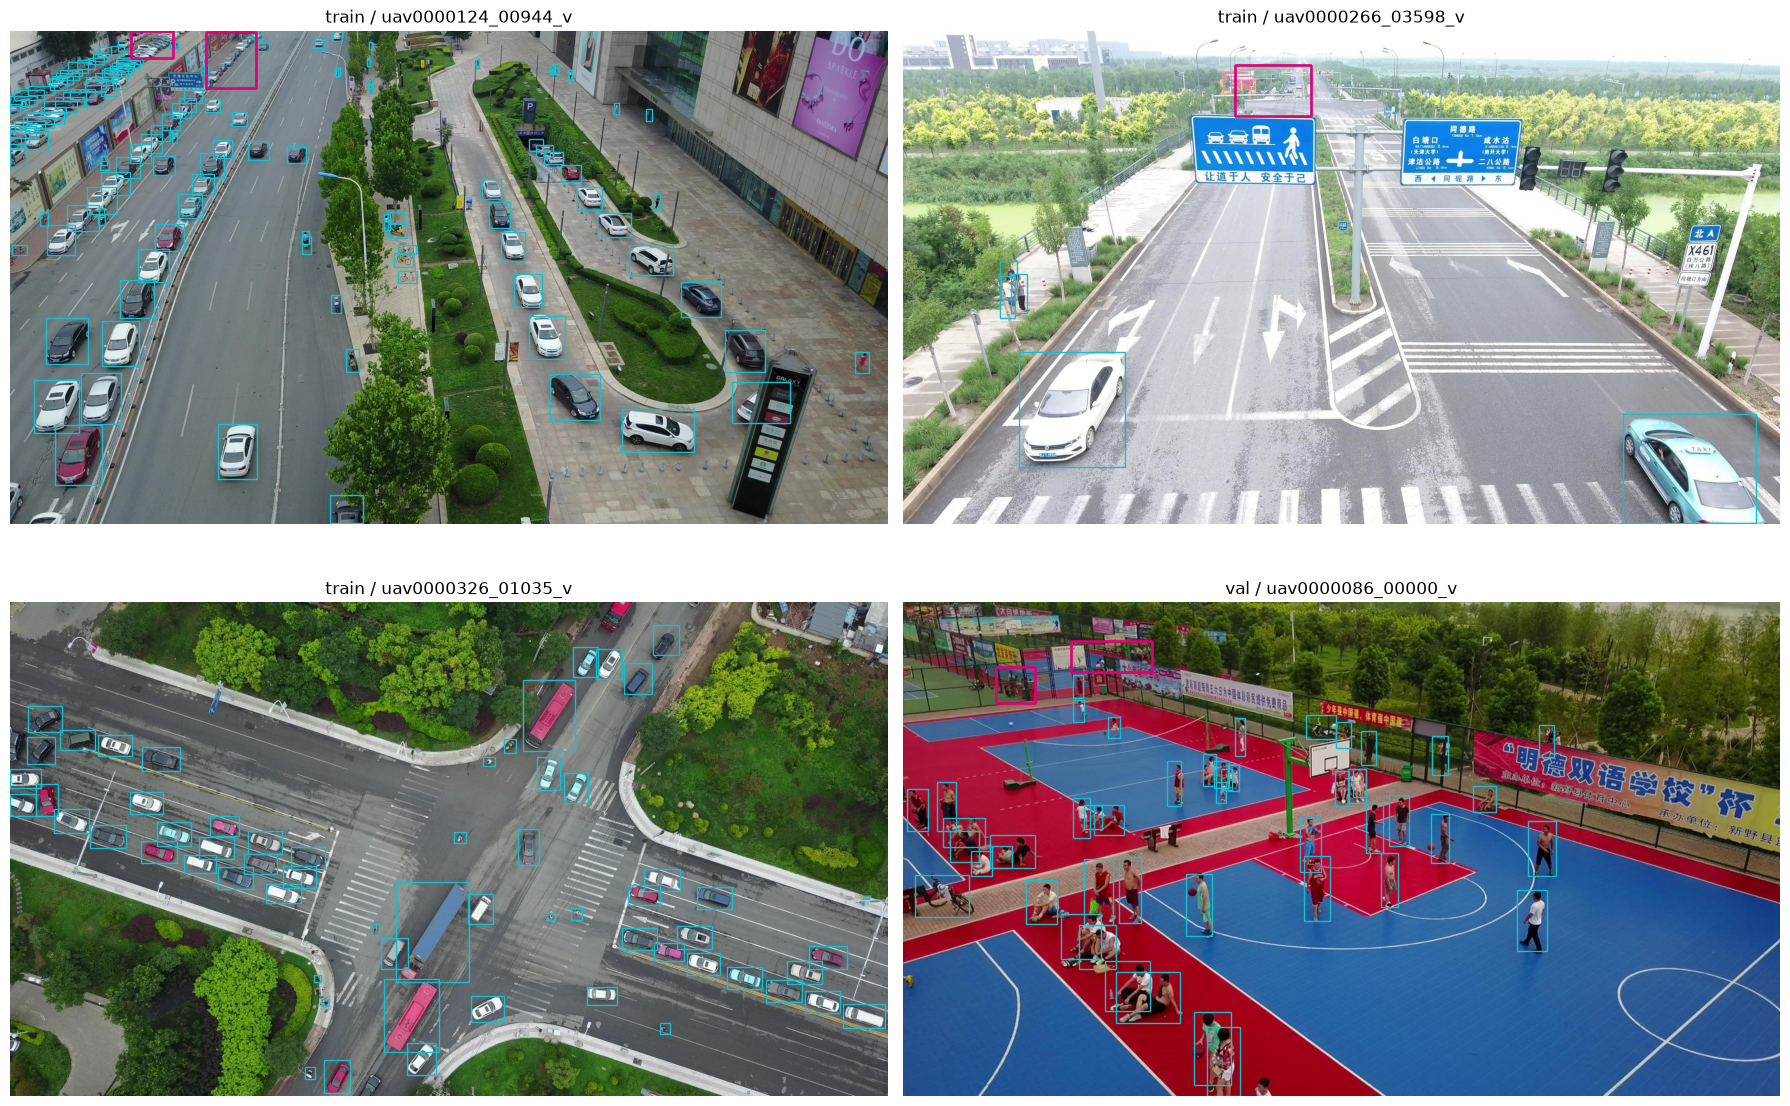

In [8]:
sample_videos = frames[["split", "video"]].groupby("split").sample(n=3, random_state=42)
sample_frames = frames.merge(sample_videos, on=["split", "video"]).groupby(["split", "video"]).sample(n=1, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for ax, (_, frame) in zip(axes.flat, sample_frames.iterrows()):
    image_path = DIRECTORY / frame["split"] / "images" / str(frame["video"]) / Path(frame["file_name"]).name
    image = cv.imread(str(image_path))
    ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))

    for annotations, color in [(correct_boxes, "#17BECF"), (ignored_boxes, "#E20074")]:
        frame_boxes = annotations.loc[annotations["split"].eq(frame["split"]) & annotations["image_id"].eq(frame["image_id"])]

        for box in frame_boxes.itertuples(index=False):
            ax.add_patch(Rectangle((box.x_min, box.y_min), box.x_max - box.x_min, box.y_max - box.y_min,
                                   fill=False, edgecolor=color, linestyle="-", linewidth=1))

    ax.set_title(f'{frame["split"]} / {frame["video"]}')
    ax.axis("off")

fig.tight_layout()
plt.show()

In [9]:
train_videos = frames.loc[frames["split"].eq("train"), "video"].unique()
val_videos = frames.loc[frames["split"].eq("val"), "video"].unique()

shared_videos = pd.Series(train_videos)
shared_videos = shared_videos.loc[shared_videos.isin(val_videos)]

if len(shared_videos) == 0:
    print("Train and validation have no shared videos.")
else:
    print(f"Shared videos: {shared_videos.tolist()}")

print(f"Train: {len(train_videos)} videos")
print(f"Validation: {len(val_videos)} videos")

Train and validation have no shared videos.
Train: 56 videos
Validation: 7 videos


## Class distribution

split,train,val
class_name,,
person,328701,50312
bicycle,40255,6022
car,505301,31821
van,46940,6842
truck,30498,1359
tricycle,41349,5487
bus,9653,264
motor,102819,12025


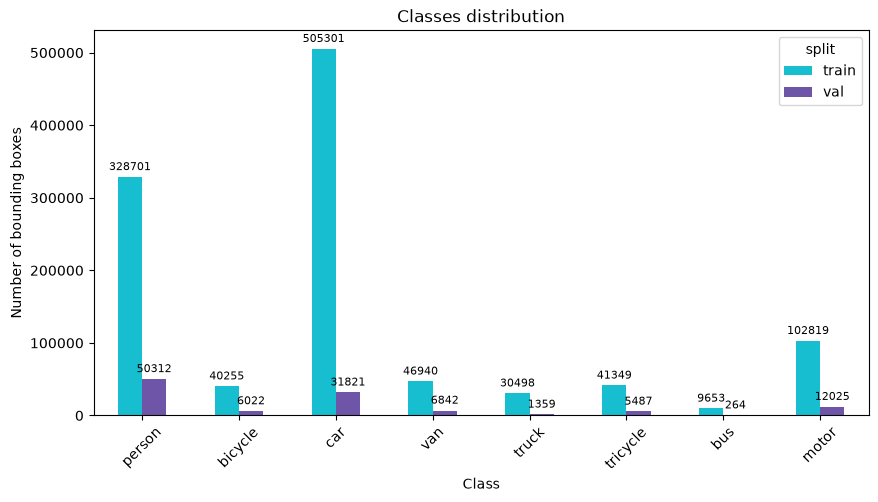

In [10]:
class_counts = pd.crosstab(correct_boxes["class_name"], correct_boxes["split"])
class_counts = class_counts.reindex(index=CLASSES, columns=["train", "val"], fill_value=0)

ax = class_counts.plot.bar(color=["#17BECF", "#6F55A8"],figsize=(10, 5), rot=45, title="Classes distribution")
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{count}" for count in bars.datavalues], padding=3, fontsize=8)

ax.set_xlabel("Class")
ax.set_ylabel("Number of bounding boxes")
display(class_counts)
plt.show()

## Object sizes

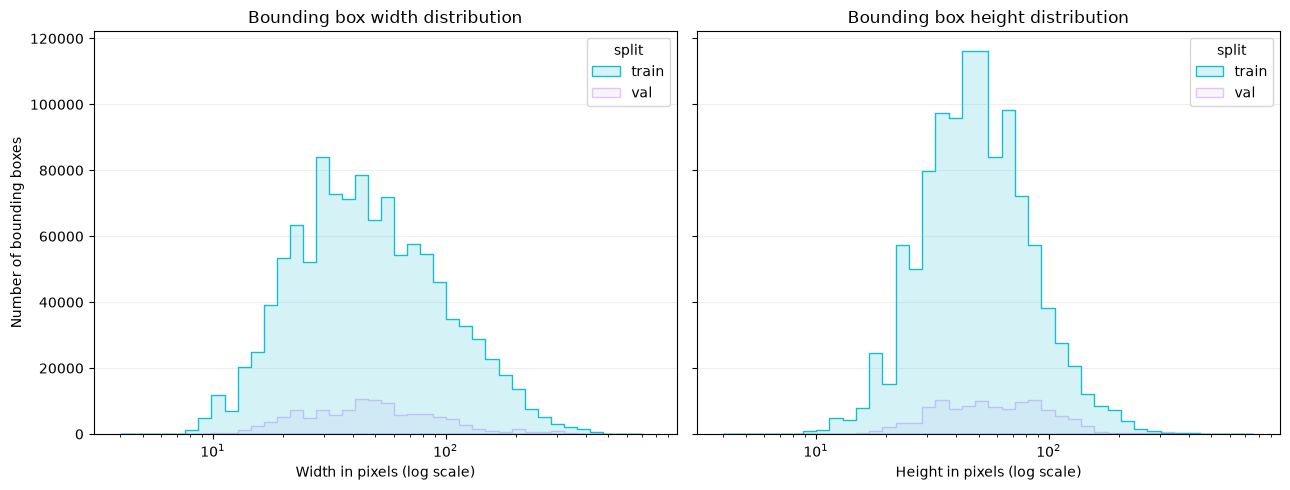

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, column, name in zip(axes,["bbox_width", "bbox_height"], ["Width", "Height"],):
    sns.histplot(data=correct_boxes, x=column, hue="split",
                 hue_order=["train", "val"], palette={"train": "#17BECF", "val": "#DFC5FE"}, bins=40,
        log_scale=True, element="step", fill=True, alpha=0.18, linewidth=1, ax=ax,
    )

    ax.set_title(f"Bounding box {name.lower()} distribution")
    ax.set_xlabel(f"{name} in pixels (log scale)")
    ax.set_ylabel("Number of bounding boxes")
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

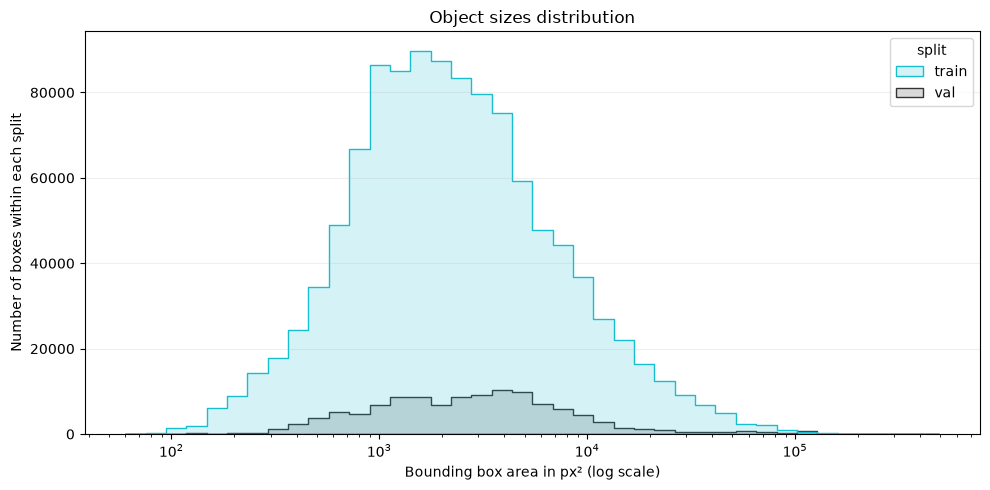

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(data=correct_boxes, x="bbox_area", hue="split", hue_order=["train", "val"], palette={"train": "#17BECF", "val": "#333333"},
    bins=40, ax=ax, log_scale=True, element="step", fill=True, alpha=0.18, linewidth=1)

ax.set_title("Object sizes distribution")
ax.set_xlabel("Bounding box area in px² (log scale)")
ax.set_ylabel("Number of boxes within each split")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

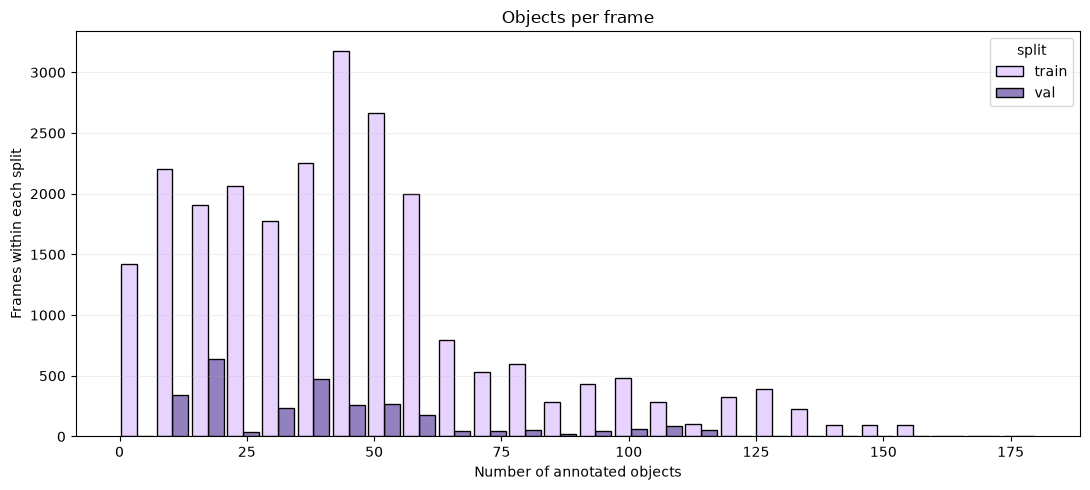

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(data=frames, x="objects_per_frame", hue="split", hue_order=["train", "val"], 
             palette={"train": "#DFC5FE", "val": "#6F55A8"}, binwidth=7,  ax=ax, multiple="dodge", shrink=0.9)

ax.set_title("Objects per frame")
ax.set_xlabel("Number of annotated objects")
ax.set_ylabel("Frames within each split")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()